# objtext_data_check:服务器上有多少可用的「物体 ↔ 文本」数据

**目的**:方向 2(区域 ↔ 文本对比预训练)需要「物体的 3D 框 + 描述它的文本 + 能加载的带位姿帧」。本报告只统计,不训练。

**一行文本算可用,要同时满足**
1. 物体在 EmbodiedScan 里有 3D 框(id 能对上);
2. 场景的帧在磁盘上;
3. 场景在 EmbodiedScan train 划分里,不在 VSI-Bench 场景里,也不在 1/20 的 holdout 里(规则同 hardneg_v1);
4. 物体至少在一帧里可见(EmbodiedScan 的 `visible_instance_ids`)。

数据来自任务 12831,`results/summary.json`,脚本 `jepa3d/tools/check_objtext_data.py`。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
d = json.load(open("../results/summary.json"))
text = d["text"]

## 1. 3D 框:哪些数据集能用

EmbodiedScan 的框覆盖 ScanNet、3RScan、Matterport3D,v2 多了 ARKitScenes。之前的 probe 只用了 ScanNet。test 划分不发布框。

In [2]:
rows = []
for key, v in d["boxes_v2"].items():
    dataset, split = key.split("/")
    disk = d["frames_on_disk"][dataset]
    rows.append({"数据集": dataset, "划分": split, "场景": v["scenes"], "有名字的框": v["boxes_named"],
                 "其中可见": v["boxes_named_visible"], "probe 用过的口径(场景内唯一类别)": v["boxes_single_instance"],
                 "帧在磁盘上的场景": f'{disk.get("scenes_all_found", 0)}/{disk["scenes"]}'})
pd.DataFrame(rows)

,数据集,划分,场景,有名字的框,其中可见,probe 用过的口径(场景内唯一类别),帧在磁盘上的场景
0,3rscan,test,157,0,0,0,1335/1335
1,3rscan,train,943,25686,19220,8562,1335/1335
2,3rscan,val,235,6408,4811,2111,1335/1335
3,arkitscenes,test,549,0,0,0,0/5047
4,arkitscenes,train,3599,68901,66438,25397,0/5047
5,arkitscenes,val,899,17005,16422,6240,0/5047
6,matterport3d,test,234,0,0,0,0/1785
7,matterport3d,train,1212,21348,18194,6507,0/1785
8,matterport3d,val,339,5919,4892,1971,0/1785
9,scannet,test,312,0,0,0,1513/1513


**读法**
- ScanNet 和 3RScan 的帧都在磁盘上。
- Matterport3D:磁盘上只有 90 个扫描的 zip,没解压,EmbodiedScan 列出的帧一个都找不到。
- ARKitScenes:磁盘上没有。
- 「有名字的框」去掉了 wall / floor / ceiling / object 等 8 个结构类和兜底类。

## 2. 只用类别名时有多少监督

不需要任何额外文本:每个可见的框配它的类别名。用点提示指定物体,就不再受「场景内唯一类别」的限制。

In [3]:
rows = []
for dataset, v in d["category_names"].items():
    rows.append({"数据集": dataset, "可用场景": v.get("scenes_usable", 0), "可用的框": v.get("boxes_usable", 0),
                 "帧缺失的场景": v.get("scenes_frames_missing", 0), "val/test 场景": v.get("scenes_embodiedscan_val_test", 0),
                 "holdout 场景": v.get("scenes_hardneg_holdout", 0)})
display(pd.DataFrame(rows))
c = d["categories_scannet_3rscan"]
print(f'ScanNet + 3RScan:{c["boxes"]} 个框,{c["categories"]} 个类别;'
      f'≥100 个框的类别 {c["categories_ge_100"]} 个,≥20 个的 {c["categories_ge_20"]} 个;'
      f'前 20 个类别占 {c["boxes_in_top20_categories"] / c["boxes"]:.0%}')
old = d["boxes_v2"]["scannet/train"]["boxes_single_instance"]
print(f'probe 当时的口径(ScanNet train,场景内唯一类别):{old} 个框 -> 现在 {c["boxes"]} 个,{c["boxes"] / old:.1f} 倍')

,数据集,可用场景,可用的框,帧缺失的场景,val/test 场景,holdout 场景
0,scannet,903,25213,0,555,55
1,3rscan,892,18101,0,392,51
2,matterport3d,0,0,1160,573,52
3,arkitscenes,0,0,3413,1448,186


ScanNet + 3RScan:43314 个框,251 个类别;≥100 个框的类别 68 个,≥20 个的 146 个;前 20 个类别占 62%
probe 当时的口径(ScanNet train,场景内唯一类别):8811 个框 -> 现在 43314 个,4.9 倍


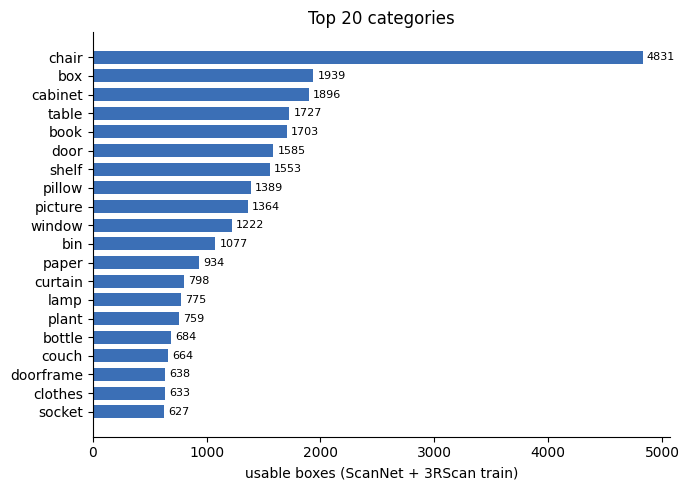

In [4]:
top = pd.DataFrame(c["top20"], columns=["类别", "框数"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.barh(top["类别"], top["框数"], color="#3b6fb6", height=0.7)
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_xlabel("usable boxes (ScanNet + 3RScan train)")
ax.set_title("Top 20 categories")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

类别分布很长尾:前 20 个类别占六成,251 个类别里只有 68 个有 100 个以上的框。之前「类别名 → 位置」的 probe 只在高频类别上有效,这个分布不会因为加了 3RScan 而改变。

## 3. 物体级文本:各来源能对上多少

`id 对上` = 文本里的物体 id 在该场景的 EmbodiedScan 框里存在;`id+类别一致` = 且类别名一致(互为子串也算)。分别按偏移 0 和 +1 测,因为原始数据集的实例 id 和 EmbodiedScan 的 `bbox_id` 不一定是同一套编号。

In [5]:
NAMES = {"es_vg_v1_train": "EmbodiedScan VG", "mmscan_caption_train": "MMScan 物体描述", "mmscan_vg_train": "MMScan VG(单目标)",
         "3rscan_prompted": "LEO 3RScan prompted", "3rscan_scanscribe": "LEO 3RScan ScanScribe",
         "sr3d+": "LEO Sr3D+", "nr3d": "LEO Nr3D", "scanrefer_train": "LEO ScanRefer"}
rows = []
for key, v in text.items():
    source, dataset = key.split("|")
    if source not in NAMES:
        continue
    single = v["rows"] - v.get("rows_no_single_target", 0)
    rows.append({"来源": NAMES[source], "数据集": dataset, "行数": v["rows"], "词数中位": v["words_median"],
                 "id+类别一致 @0": f'{v["id_and_category_offset0"] / max(single, 1):.0%}',
                 "id+类别一致 @+1": f'{v["id_and_category_offset1"] / max(single, 1):.0%}',
                 "可用行": v.get("rows_usable_visible", 0), "可用物体": v["usable_objects"],
                 "例子": v["examples"][0][:110]})
table = pd.DataFrame(rows).sort_values(["数据集", "来源"]).reset_index(drop=True)
table

,来源,数据集,行数,词数中位,id+类别一致 @0,id+类别一致 @+1,可用行,可用物体,例子
0,EmbodiedScan VG,3rscan,77539,9.0,100%,18%,53667,5581,choose the cabinet that is closer to the flush
1,LEO 3RScan ScanScribe,3rscan,89638,73.0,0%,0%,52518,5560,This is a soap dish. It is supported by the sink.
2,LEO 3RScan prompted,3rscan,110859,36.0,78%,18%,62915,22474,The floor is made of wooden material and is flat in shape. It is brown in color.
3,MMScan VG(单目标),3rscan,260269,16.0,100%,16%,154560,16510,"The metallic silver shower, which belongs to the bathroom fixtures, is made of stainless steel."
4,MMScan 物体描述,3rscan,15472,91.0,100%,29%,10558,10558,"The bathtub is a standard, rectangular fixture made of porcelain material. It has a smooth, white surface, whi"
5,EmbodiedScan VG,matterport3d,35246,9.0,100%,13%,0,0,the window that is farthest from the pipe
6,MMScan VG(单目标),matterport3d,213189,16.0,100%,10%,0,0,"The sleek rod, characterized by its cylindrical shape and black metallic sheen, is a tall and slender stainles"
7,MMScan 物体描述,matterport3d,17266,93.0,100%,22%,0,0,"This pipe is made of stainless steel or chrome. It is cylindrical in shape with a reflective surface, crafted"
8,EmbodiedScan VG,scannet,121229,9.0,99%,19%,109306,7943,the board that is beside the door
9,LEO Nr3D,scannet,30037,10.0,44%,76%,21879,3394,The plant at the far right hand side of the bookcase tucked in the furthest corner of the desk


**读法**
- **EmbodiedScan VG、MMScan(描述和 VG)**:id 就是 `bbox_id`,偏移 0 下类别一致率接近 100%,可直接用。
- **LEO 3RScan prompted**:偏移 0 下全部行的 78% 一致;只看 id 能对上的行是 93%(86,034 / 92,205),可用。它也描述 wall / floor,所以「可用物体」比第 2 节的框数多。**ScanScribe** 文件里没有类别字段,无法用类别验证;它和 prompted 同属 3RScan 的 id 体系,但这一点我没有独立验证。
- **Sr3D+ / Nr3D / ScanRefer(ScanNet)**:偏移 +1 明显好于 0,但一致率只有七成左右。**上表这三行的「可用行 / 可用物体」是按偏移 0 算的,不能用**。要用这三份,得先用几何方法(ScanNet 实例分割和框的重叠)确认 id 对应关系。
- **Matterport3D 的所有文本**:框和文本都有,但帧没解压,可用数为 0。
- MMScan VG 的 test 划分不带目标 id;train 里约 16% 的行是多目标或无目标,已排除。
- ScanRefer val 的 141 个场景属于 EmbodiedScan test(= ScanNet 官方 val),没有框。

In [6]:
ok = table[~table["来源"].isin(["LEO Sr3D+", "LEO Nr3D", "LEO ScanRefer"])]
ok = ok[ok["可用行"] > 0]
summary = ok.groupby("数据集")[["可用行"]].sum()
summary.loc["合计"] = summary.sum()
display(ok[["来源", "数据集", "词数中位", "可用行", "可用物体"]])
summary

,来源,数据集,词数中位,可用行,可用物体
0,EmbodiedScan VG,3rscan,9.0,53667,5581
1,LEO 3RScan ScanScribe,3rscan,73.0,52518,5560
2,LEO 3RScan prompted,3rscan,36.0,62915,22474
3,MMScan VG(单目标),3rscan,16.0,154560,16510
4,MMScan 物体描述,3rscan,91.0,10558,10558
8,EmbodiedScan VG,scannet,9.0,109306,7943
12,MMScan VG(单目标),scannet,16.0,239824,23951
13,MMScan 物体描述,scannet,95.0,22415,22415


,可用行
数据集,
3rscan,334218
scannet,371545
合计,705763


注意同一个物体会被多个来源描述,「可用物体」不能跨来源相加。物体数的上限就是第 2 节的框数。

## 4. 评测泄漏

In [7]:
print("VSI-Bench 场景数:", d["eval_scenes"])
print("其中落在 EmbodiedScan train 的:", d["eval_scenes_in_embodiedscan_train"])
print("场景级描述(SceneVerse ScanNet):", d["scene_captions"])

VSI-Bench 场景数: {'vsibench_test_posed_f8': 122, 'vsibench_debiased_posed_f8': 111}
其中落在 EmbodiedScan train 的: []
场景级描述(SceneVerse ScanNet): {'sceneverse_scannet_scenes': 1510, 'captions': 4530}


- VSI-Bench 用到的场景没有一个在 EmbodiedScan train 里,所以用 train 的框和文本不会泄漏到 VSI-Bench。
- SceneVerse 的 `scannet_scene_cap.json` 是整场景描述,没有物体 id,不能做区域 ↔ 文本。`sceneverse/3rscan.zip` 没解压,这次没看里面。

## 5. 结论

1. **不用下载任何东西,就有约 1,800 个场景、4.3 万个带类别名的可见框**(ScanNet 903 + 3RScan 892 个场景)。按 probe 当时的口径只有 8,811 个框。
2. **可直接用的物体级文本约 70 万行**,主要是 MMScan VG 和 EmbodiedScan VG。短文本(9–16 词)多是「门旁边的板子」这类关系描述,长文本(MMScan 描述,90 多词)讲外观。
3. **场景数只翻了一倍**(958 → 约 1,800)。probe 过拟合的原因是场景少,这一点只缓解了一部分。
4. **再往上加数据要动磁盘**:解压 Matterport3D(+1,160 个 train 区域,约 1.8 万个可见框),或下载 ARKitScenes(+3,413 个场景,约 6.6 万个可见框)。两者都没做,需要你决定。

## 6. 这份检查没覆盖的

- **3RScan 的帧没实际加载过**:只确认了文件存在。它没有 `frame_stats`(质量过滤用),图像朝向和分辨率也没核对,我们的 QA 训练集里也没有 3RScan 场景。
- **「可见」口径偏松**:probe 的 README 记过,EmbodiedScan 标为可见的物体里只有约 30% 中心落在该帧内。实际每次只采 8 帧,能用点提示指到的物体会比表里少。
- **文本质量没抽查**:只看了每个来源的前几条。MMScan 和 3RScan prompted 是模型生成的描述。
- holdout 规则对 3RScan 等也按同一个哈希切了 1/20,只是为了统计口径一致。